# Ejercicio 3: Regresión lineal múltiple — AUTO

## Enunciado

Una organización de consumidores quiere desarrollar un modelo de regresión para pronosticar el rendimiento de gasolina (medido en millas por galón) con base en la potencia del motor y el peso del automóvil en libras. Se seleccionó una muestra de 50 modelos recientes de automóvil y se registraron los datos en el archivo `../Docs/AUTO.xls`.

**Pregunta:** Elabore una estimación para la media de las millas por galón correspondientes a los automóviles con 60 caballos de potencia y con peso de 2,000 libras.

## Resolución paso a paso

1. **Identificar las variables.** `MPG` es el rendimiento de gasolina en millas por galón; `Horsepower` es la potencia del motor en caballos de fuerza, y `Weight` es el peso en libras. Se tienen 50 automóviles.
2. **Elegir el modelo.** Como el rendimiento se estima simultáneamente a partir de dos variables cuantitativas, se ajusta una regresión lineal múltiple: $MPG_i = \beta_0 + \beta_1 Horsepower_i + \beta_2 Weight_i + \varepsilon_i$.
3. **Estimar los coeficientes.** Se usa mínimos cuadrados, que elige los coeficientes que minimizan la suma de residuos al cuadrado. El código presenta la ecuación estimada, los errores estándar, las pruebas t individuales y $R^2$.
4. **Calcular la media estimada y su intervalo.** Se evalúa el modelo en `Horsepower = 60` y `Weight = 2000`. Para la media de MPG, se calcula el intervalo de confianza bilateral del 95% con la distribución t y $50-3=47$ grados de libertad. No es un intervalo de predicción para un automóvil individual; ese intervalo sería más ancho al incluir la variabilidad individual.
5. **Revisar los gráficos.** Los diagramas de dispersión muestran las relaciones de MPG con cada predictor. Los gráficos de valores observados y ajustados y de residuos ayudan a evaluar el ajuste, linealidad, varianza residual y normalidad. Los gráficos son diagnósticos, no pruebas definitivas. La independencia debe justificarse a partir de cómo se seleccionaron los automóviles.

Los coeficientes describen asociaciones manteniendo constante la otra variable explicativa. El modelo no prueba por sí mismo que la potencia o el peso causen los cambios estimados en MPG.

Archivo: C:\Users\Gasti\Desktop\MPG\Docs\AUTO.xls
Automóviles: 50


,MPG,Horsepower,Weight
0,43.1,48,1985
1,19.9,110,3365
2,19.2,105,3535
3,17.7,165,3445
4,18.1,139,3205


,count,mean,std,min,25%,50%,75%,max
MPG,50.0,28.542,8.171431,15.5,20.825,27.75,34.625,46.6
Horsepower,50.0,90.840,27.258670,48.0,68.500,85.00,104.500,165.0
Weight,50.0,2756.520,635.050994,1755.0,2211.250,2699.00,3235.000,4360.0


,Coeficiente,Error estándar,t,p-valor
Intercepto,58.157082,2.658248,21.877973,2.760997e-26
Horsepower (HP),-0.117525,0.032643,-3.600280,7.631284e-04
Weight (libras),-0.006871,0.001401,-4.903494,1.164907e-05


R² = 0.7494 | R² ajustado = 0.7388 | Error estándar residual = 4.177 MPG
Ecuación estimada: MPG_hat = 58.1571 + (-0.11753)·Horsepower + (-0.006871)·Weight

RESULTADO: 60 caballos de fuerza y 2,000 libras
Media estimada: 37.364 millas por galón
IC del 95% para la media: [35.453, 39.276] millas por galón


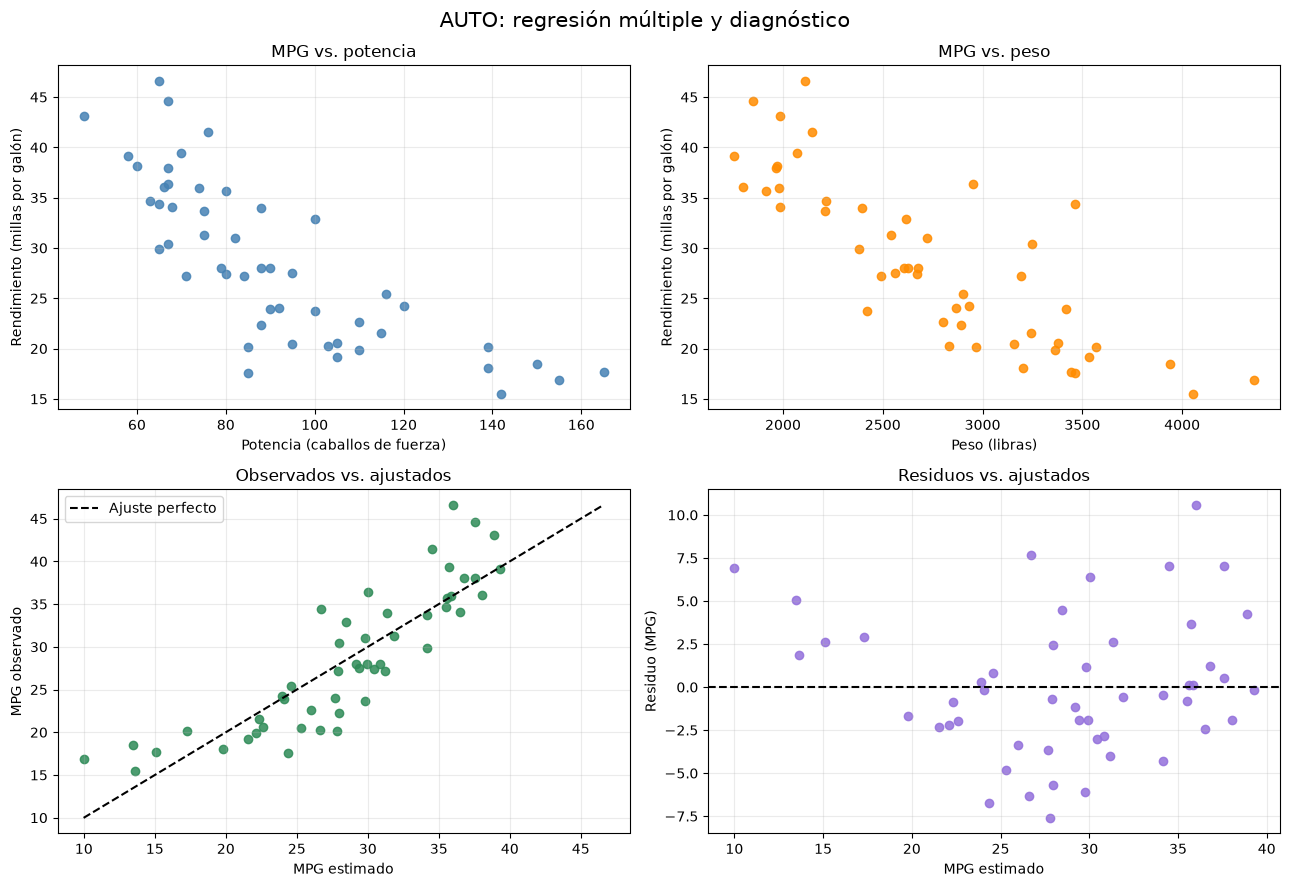

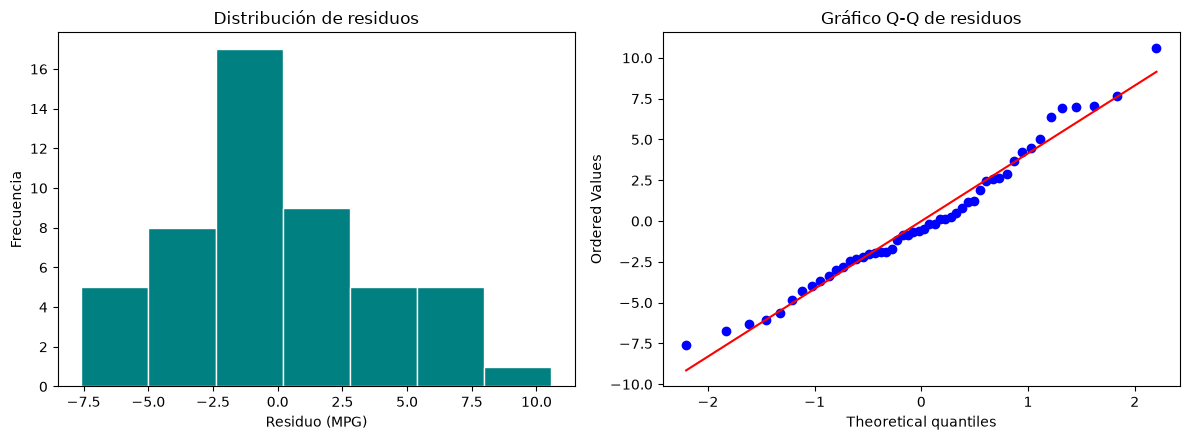

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# Busca AUTO.xls desde la raíz del proyecto o desde la carpeta Regresion_lineal.
rutas = [Path("Docs/AUTO.xls"), Path("../Docs/AUTO.xls")]
archivo = next((ruta for ruta in rutas if ruta.is_file()), None)
if archivo is None:
    raise FileNotFoundError(
        "No se encontró AUTO.xls. Comprueba que el archivo esté en la carpeta Docs del proyecto."
    )

datos = pd.read_excel(archivo)
columnas = ["MPG", "Horsepower", "Weight"]
faltantes = set(columnas).difference(datos.columns)
if faltantes:
    raise ValueError(f"Faltan columnas en AUTO.xls: {sorted(faltantes)}")
if len(datos) != 50 or datos[columnas].isna().any().any():
    raise ValueError("Se esperaban 50 observaciones completas en MPG, Horsepower y Weight.")

print(f"Archivo: {archivo.resolve()}")
print(f"Automóviles: {len(datos)}")
display(datos.head())
display(datos.describe().T)

# Modelo: MPG = beta_0 + beta_1*Horsepower + beta_2*Weight + error.
y = datos["MPG"].to_numpy(dtype=float)
X = np.column_stack(
    [
        np.ones(len(datos)),
        datos["Horsepower"].to_numpy(dtype=float),
        datos["Weight"].to_numpy(dtype=float),
    ]
)
n, k = X.shape
gl_error = n - k
beta, _, _, _ = np.linalg.lstsq(X, y, rcond=None)
ajustados = X @ beta
residuos = y - ajustados
sse = float(residuos @ residuos)
mse = sse / gl_error
cov_beta = mse * np.linalg.inv(X.T @ X)
ee_beta = np.sqrt(np.diag(cov_beta))
t_beta = beta / ee_beta
p_beta = 2 * stats.t.sf(np.abs(t_beta), gl_error)
r2 = 1 - sse / np.sum((y - y.mean()) ** 2)
r2_ajustado = 1 - (1 - r2) * (n - 1) / gl_error

tabla_coeficientes = pd.DataFrame(
    {"Coeficiente": beta, "Error estándar": ee_beta, "t": t_beta, "p-valor": p_beta},
    index=["Intercepto", "Horsepower (HP)", "Weight (libras)"],
)
display(tabla_coeficientes)
print(f"R² = {r2:.4f} | R² ajustado = {r2_ajustado:.4f} | Error estándar residual = {np.sqrt(mse):.3f} MPG")
print(f"Ecuación estimada: MPG_hat = {beta[0]:.4f} + ({beta[1]:.5f})·Horsepower + ({beta[2]:.6f})·Weight")

# IC del 95% para la media cuando Horsepower=60 y Weight=2,000 lb.
x0 = np.array([1.0, 60.0, 2000.0])
media = float(x0 @ beta)
ee_media = np.sqrt(mse * float(x0 @ np.linalg.inv(X.T @ X) @ x0))
t_critico = stats.t.ppf(0.975, gl_error)
li, ls = media - t_critico * ee_media, media + t_critico * ee_media
print("\nRESULTADO: 60 caballos de fuerza y 2,000 libras")
print(f"Media estimada: {media:.3f} millas por galón")
print(f"IC del 95% para la media: [{li:.3f}, {ls:.3f}] millas por galón")

# Gráficos descriptivos y de diagnóstico.
fig, ax = plt.subplots(2, 2, figsize=(13, 9))
ax[0, 0].scatter(datos["Horsepower"], y, color="steelblue", alpha=0.85)
ax[0, 0].set(title="MPG vs. potencia", xlabel="Potencia (caballos de fuerza)", ylabel="Rendimiento (millas por galón)")
ax[0, 1].scatter(datos["Weight"], y, color="darkorange", alpha=0.85)
ax[0, 1].set(title="MPG vs. peso", xlabel="Peso (libras)", ylabel="Rendimiento (millas por galón)")
ax[1, 0].scatter(ajustados, y, color="seagreen", alpha=0.85)
extremos = [min(y.min(), ajustados.min()), max(y.max(), ajustados.max())]
ax[1, 0].plot(extremos, extremos, "k--", label="Ajuste perfecto")
ax[1, 0].set(title="Observados vs. ajustados", xlabel="MPG estimado", ylabel="MPG observado")
ax[1, 0].legend()
ax[1, 1].scatter(ajustados, residuos, color="mediumpurple", alpha=0.85)
ax[1, 1].axhline(0, color="black", linestyle="--")
ax[1, 1].set(title="Residuos vs. ajustados", xlabel="MPG estimado", ylabel="Residuo (MPG)")
for eje in ax.flat:
    eje.grid(alpha=0.25)
fig.suptitle("AUTO: regresión múltiple y diagnóstico", fontsize=15)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].hist(residuos, bins="auto", edgecolor="white", color="teal")
ax[0].set(title="Distribución de residuos", xlabel="Residuo (MPG)", ylabel="Frecuencia")
stats.probplot(residuos, dist="norm", plot=ax[1])
ax[1].set(title="Gráfico Q-Q de residuos")
fig.tight_layout()
plt.show()

## Conclusión

Con los 50 automóviles de la muestra, el modelo estima para un automóvil de 60 caballos de fuerza y 2,000 libras una media de aproximadamente **37.36 millas por galón**. El intervalo de confianza del 95% para esa media es aproximadamente **35.45 a 39.28 millas por galón**. El intervalo se refiere a la media de los automóviles con estas características; no describe el rango esperado para cada automóvil individual.